# 04 · Customer segmentation: who books these hotels

**Business question.** Capacity is the binding constraint on three nights out of four
(notebook 02), so revenue depends on *which* customers get the rooms. Who are they, how different
are they between a city hotel and a resort, and can the segments be recognised at the moment a
request arrives?

**Approach.**

1. Describe each booking with 17 features that are known when the request arrives (trip shape,
   party, price relative to the month, how it was sold). No outcome, no post-booking columns, no
   `country` (partly filled in at check-in, notebook 03).
2. Cluster each hotel separately with k-means; choose k with three criteria (compactness,
   separation, **stability** under resampling) and interpretability.
3. Check that the segments are not an artefact of k-means (Gaussian mixture, hierarchical
   clustering) and measure how much they add to the obvious split by sales segment.
4. Make them explainable with a shallow decision tree on raw fields.

Value and risk of each persona, peak nights, partners and recommendations follow in notebook 05.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.tree import DecisionTreeClassifier, export_text

sys.path.insert(0, str(Path.cwd().parent))
from src.simulator import load_train, ROOMS
from src.plotting import PERSONA_COLORS
from src.customers import (PERSONA_ORDER, add_block_size, booking_frame, fit_personas, kpi,
                           segment_features, standardize)
from src import plotting as P

P.setup()
pd.set_option("display.width", 180); pd.set_option("display.max_columns", 30)
HOTELS = list(ROOMS)
full = add_block_size(load_train())
data = {h: booking_frame(full, h) for h in HOTELS}
F = {h: segment_features(data[h]) for h in HOTELS}
X = {h: standardize(F[h]) for h in HOTELS}
{h: X[h].shape for h in HOTELS}

{'Downtown Hotel': (51575, 17), 'Seaside Hotel': (26557, 17)}

## 1 · How many segments?

For k = 3…10 and each hotel: **inertia** (elbow), **silhouette** on a 10,000-row sample, and
**stability**: k-means refitted on three random halves of the data and compared with the full fit
(adjusted Rand index, 1 = identical partition). A segmentation that changes when the data is
resampled cannot support business decisions.

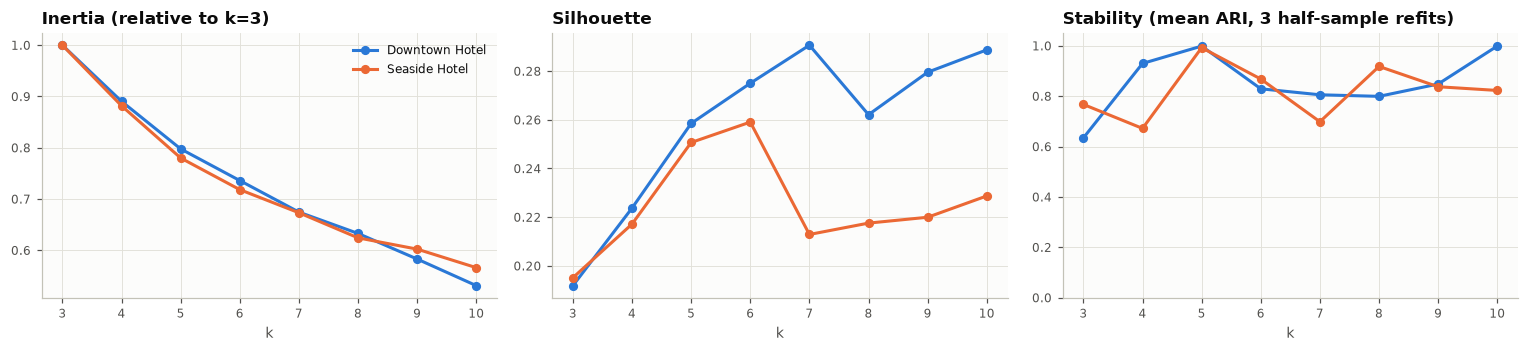

Downtown Hotel                          Seaside Hotel                         
          inertia silhouette stability_ari       inertia silhouette stability_ari
k                                                                                
3      672609.552      0.192         0.634    346048.101      0.195         0.767
4      598986.889      0.224         0.930    305147.000      0.217         0.672
5      536552.655      0.259         0.999    269917.151      0.251         0.992
6      495044.396      0.275         0.829    248564.818      0.259         0.868
7      453662.401      0.291         0.805    232950.066      0.213         0.698
8      425649.314      0.262         0.799    216020.878      0.218         0.918
9      392058.021      0.280         0.848    208405.294      0.220         0.837
10     357181.637      0.289         0.999    195901.574      0.229         0.823

In [2]:
KS = range(3, 11)
sel = {}
for h in HOTELS:
    rng = np.random.default_rng(0)
    sample = rng.choice(len(X[h]), 10_000, replace=False)
    rows = []
    for k in KS:
        km = KMeans(k, n_init=10, random_state=0).fit(X[h])
        ari = [adjusted_rand_score(km.labels_, KMeans(k, n_init=10, random_state=r).fit(
               X[h][rng.choice(len(X[h]), len(X[h]) // 2, replace=False)]).predict(X[h])) for r in (1, 2, 3)]
        rows.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(X[h][sample], km.labels_[sample]),
                     "stability_ari": np.mean(ari)})
    sel[h] = pd.DataFrame(rows).set_index("k")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.3))
for h in HOTELS:
    for ax, col in zip(axes, ["inertia", "silhouette", "stability_ari"]):
        v = sel[h][col] / (sel[h][col].iloc[0] if col == "inertia" else 1)
        ax.plot(KS, v, marker="o", color=P.HOTEL_COLORS[h], label=h)
axes[0].set(title="Inertia (relative to k=3)", xlabel="k"); axes[1].set(title="Silhouette", xlabel="k")
axes[2].set(title="Stability (mean ARI, 3 half-sample refits)", xlabel="k", ylim=(0, 1.05)); axes[0].legend()
plt.tight_layout(); plt.show()
pd.concat(sel, axis=1).round(3)

No k is best on every criterion, as usual with real customer data. Silhouette peaks at k = 7 for
Downtown (0.29) and stays flat around 0.21–0.26 for Seaside; very small k (5) is the most stable
but merges families into other groups. The rule used: **the smallest k at which every
business-relevant persona separates, with silhouette near its best and stability ARI above 0.8**.
That gives **k = 7 for Downtown** (silhouette 0.29, ARI 0.81) and **k = 8 for Seaside**
(silhouette 0.22, ARI 0.92). Each cluster is named from its centroid with fixed rules
(`src/customers.name_cluster`); at Seaside two clusters are online couples (shorter and longer
stays) and share the name.

In [3]:
K = {"Downtown Hotel": 7, "Seaside Hotel": 8}
for h in HOTELS:
    data[h]["persona"], km = fit_personas(data[h], K[h])
    sizes = pd.Series(km.labels_).value_counts(normalize=True).sort_index()
    names = pd.Series(data[h].persona.values).groupby(km.labels_).first()
    print(h, "| clusters:", "; ".join(f"{c}: {names[c]} ({sizes[c]:.0%})" for c in sizes.index))
PERSONAS = {h: [p for p in PERSONA_ORDER if p in set(data[h].persona)] for h in HOTELS}
pd.concat({h: data[h].persona.value_counts(normalize=True).reindex(PERSONA_ORDER) for h in HOTELS}, axis=1).round(3)

Downtown Hotel | clusters: 0: Groups and agency blocks (17%); 1: Last-minute direct guests (6%); 2: Contracts / allotments (5%); 3: Online leisure couples (37%); 4: Business / corporate (5%); 5: Tour-operator holidays (24%); 6: Families (6%)
Seaside Hotel | clusters: 0: Contracts / allotments (5%); 1: Online leisure couples (15%); 2: Last-minute direct guests (14%); 3: Business / corporate (6%); 4: Online leisure couples (21%); 5: Groups and agency blocks (16%); 6: Tour-operator holidays (16%); 7: Families (8%)


,Downtown Hotel,Seaside Hotel
persona,,
Online leisure couples,0.369,0.361
Families,0.059,0.083
Tour-operator holidays,0.243,0.156
Contracts / allotments,0.046,0.047
Last-minute direct guests,0.063,0.137
Business / corporate,0.048,0.056
Groups and agency blocks,0.173,0.160


## 2 · Are the segments real, or an artefact of k-means?

The same data is clustered with two other algorithms at the same k: a **Gaussian mixture**
(soft, elliptical clusters) and **Ward hierarchical clustering** (on a 12,000-row sample, as it
scales quadratically). If the partitions agree, the segments are a property of the data. As a
reference, the table also shows how much of the persona partition the **sales segment alone**
already explains.

In [4]:
rows = []
for h in HOTELS:
    km_labels = data[h].persona.to_numpy()
    gm = GaussianMixture(K[h], covariance_type="diag", random_state=0, n_init=3).fit(X[h]).predict(X[h])
    idx = np.random.default_rng(1).choice(len(X[h]), 12_000, replace=False)
    ward = AgglomerativeClustering(K[h], linkage="ward").fit_predict(X[h][idx])
    rows.append({"hotel": h, "k": K[h],
                 "ARI k-means vs Gaussian mixture": adjusted_rand_score(km_labels, gm),
                 "ARI k-means vs Ward (sample)": adjusted_rand_score(km_labels[idx], ward),
                 "ARI k-means vs sales segment only": adjusted_rand_score(km_labels, data[h].sales_segment)})
pd.DataFrame(rows).set_index("hotel").round(3)

,k,ARI k-means vs Gaussian mixture,ARI k-means vs Ward (sample),ARI k-means vs sales segment only
hotel,,,,
Downtown Hotel,7,0.979,0.872,0.811
Seaside Hotel,8,0.728,0.870,0.808


**The segments are robust.** At Downtown the Gaussian mixture reproduces the k-means personas
almost exactly (ARI 0.98) and Ward clustering closely (0.87); at Seaside agreement is good (0.73
and 0.87), with the differences concentrated on the border between online couples and families.

**They are more than the sales segment.** The sales segment alone explains a large part of the
partition (ARI ~0.81), as expected: how a booking is sold says a lot about who is behind it. The
clustering adds what cuts across channels: families (any channel, children, larger rooms, +40%
price), contracts/allotments (contract guest type), and the split between agency blocks and
individual bookings inside the tour-operator channel.

## 3 · What defines each persona

Colour = deviation from the hotel mean in standard deviations; number = mean of the raw feature.

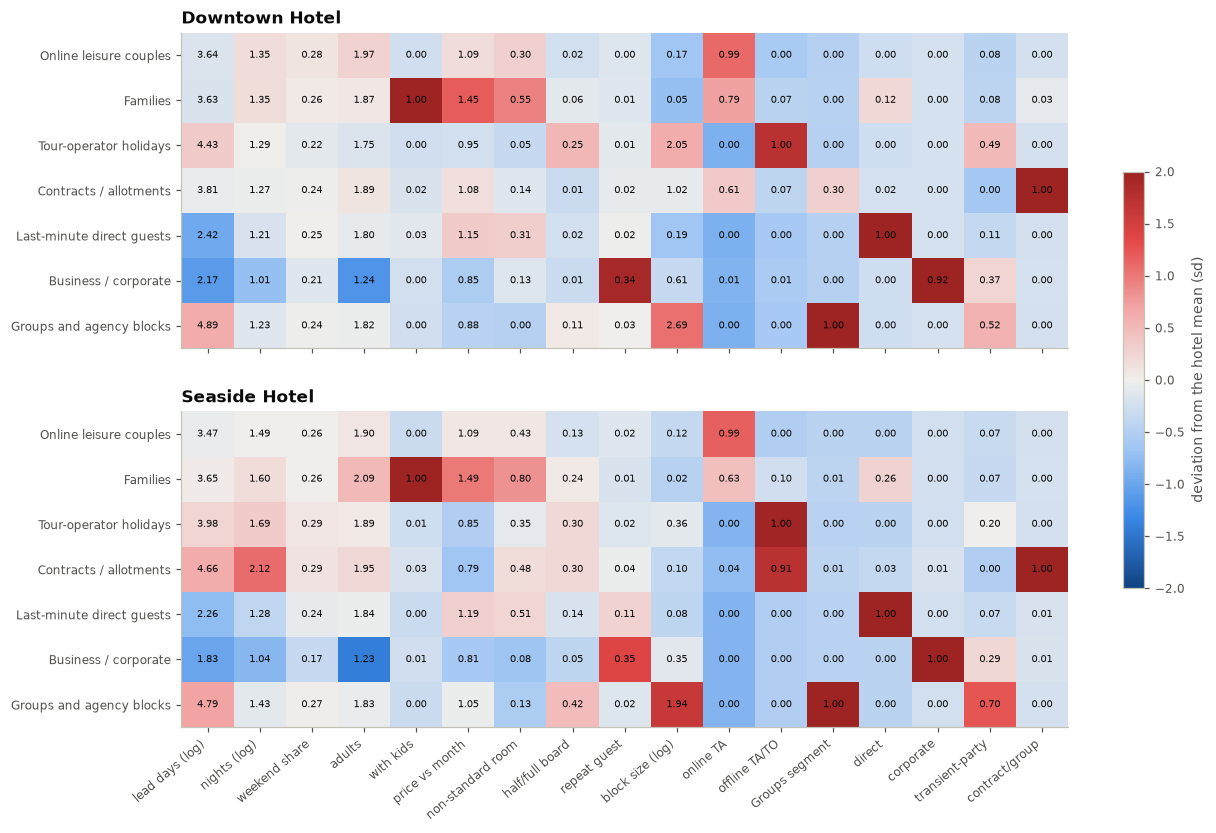

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(13, 8.2))
for ax, h in zip(axes, HOTELS):
    z = pd.DataFrame(X[h], columns=F[h].columns).groupby(data[h].persona.values).mean().reindex(PERSONAS[h])
    means = F[h].groupby(data[h].persona.values).mean().reindex(PERSONAS[h])
    im = ax.imshow(z.values, cmap=P.DIVERGING, vmin=-2, vmax=2, aspect="auto")
    ax.set_xticks(range(z.shape[1]), z.columns if h == HOTELS[-1] else [], rotation=40, ha="right")
    ax.set_yticks(range(len(z)), z.index); ax.grid(False); ax.set_title(h)
    for (r, c), v in np.ndenumerate(means.values):
        ax.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=6.5)
fig.colorbar(im, ax=axes, shrink=.6, label="deviation from the hotel mean (sd)")
P.save(fig, "persona_profiles")
plt.show()

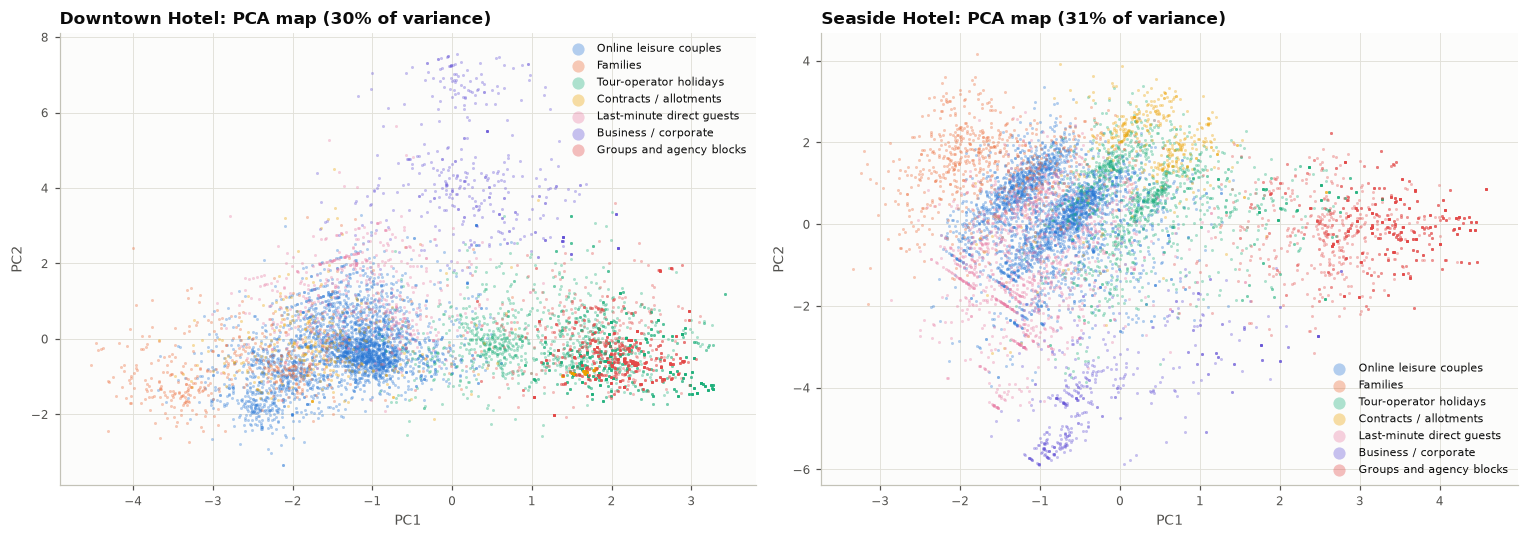

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, h in zip(axes, HOTELS):
    pca = PCA(2, random_state=0).fit(X[h])
    idx = np.random.default_rng(0).choice(len(X[h]), 8000, replace=False)
    Z = pca.transform(X[h][idx])
    for p in PERSONAS[h]:
        m = data[h].persona.values[idx] == p
        ax.scatter(Z[m, 0], Z[m, 1], s=4, alpha=.35, color=PERSONA_COLORS[p], label=p)
    ax.set(title=f"{h}: PCA map ({pca.explained_variance_ratio_.sum():.0%} of variance)", xlabel="PC1", ylabel="PC2")
    ax.legend(markerscale=4, fontsize=7)
plt.tight_layout(); plt.show()

The first principal component runs from individual bookings with children (left) to large
blocks booked months ahead (right): it is essentially *individual guest vs. block*. Business
travellers separate on the second axis (single adults, short lead, many repeat guests). Online
couples, direct guests and tour operators overlap in the middle of the map: they differ in how
they buy more than in the shape of their trip, which is why the heat map, not the 2-D map, is the
right way to read them.

## 4 · Explainable in four questions

A persona is only useful operationally if a front-desk manager can assign it. A decision tree of
depth 4 on **raw fields** (segment, guest type, meal, party, lead time, nights, block size) is
trained to reproduce the clusters.

In [7]:
def raw_fields(d):
    return pd.get_dummies(d[["sales_segment", "guest_type", "meal"]], dtype=int).assign(
        kids=d.kids, adults=d.adults, days_ahead=d.days_ahead, nights=d.nights, block=d.block, repeat=d.repeat)


trees = {}
for h in HOTELS:
    R = raw_fields(data[h])
    trees[h] = DecisionTreeClassifier(max_depth=4, min_samples_leaf=150, random_state=0).fit(R, data[h].persona)
    print(f"{h}: a depth-4 tree on raw fields reproduces the persona of {trees[h].score(R, data[h].persona):.1%} of bookings")
print()
print(export_text(trees["Seaside Hotel"], feature_names=list(raw_fields(data["Seaside Hotel"]).columns)))

Downtown Hotel: a depth-4 tree on raw fields reproduces the persona of 98.0% of bookings
Seaside Hotel: a depth-4 tree on raw fields reproduces the persona of 93.8% of bookings

|--- sales_segment_Online TA <= 0.50
|   |--- sales_segment_Groups <= 0.50
|   |   |--- sales_segment_Direct <= 0.50
|   |   |   |--- sales_segment_Corporate <= 0.50
|   |   |   |   |--- class: Tour-operator holidays
|   |   |   |--- sales_segment_Corporate >  0.50
|   |   |   |   |--- class: Business / corporate
|   |   |--- sales_segment_Direct >  0.50
|   |   |   |--- kids <= 0.50
|   |   |   |   |--- class: Last-minute direct guests
|   |   |   |--- kids >  0.50
|   |   |   |   |--- class: Families
|   |--- sales_segment_Groups >  0.50
|   |   |--- days_ahead <= 9.50
|   |   |   |--- class: Groups and agency blocks
|   |   |--- days_ahead >  9.50
|   |   |   |--- block <= 1.50
|   |   |   |   |--- class: Groups and agency blocks
|   |   |   |--- block >  1.50
|   |   |   |   |--- class: Groups and agency bl

A four-level tree on raw fields assigns the right persona to **98% of Downtown and 94% of Seaside
bookings**. The first questions are always the sales segment and the guest type; children, lead
time and length of stay refine the rest. A persona can be computed live for every request, and
can be put in words for a revenue manager.

## 5 · Persona cards

*yield* = revenue actually earned per requested room-night: it combines price and cancellation
risk, and it is the number that matters when rooms are scarce.

In [8]:
cards = {}
for h in HOTELS:
    d = data[h]
    c = d.groupby("persona").apply(kpi, ref=d, include_groups=False).reindex(PERSONAS[h])
    c["avg_block"] = d.groupby("persona").block.mean()
    c["booked_last_30d"] = (d.days_ahead <= 30).groupby(d.persona).mean()
    c["rate_vs_month"] = d.groupby("persona").rate_idx.median()
    c["top_agent_share"] = d.groupby("persona").agent_id.agg(lambda s: s.value_counts(normalize=True).iloc[0])
    cards[h] = c
fmt = {c: "{:.0%}" for c in ["cancel_rate", "share_requested_room_nights", "revenue_share", "booked_last_30d", "top_agent_share"]}
fmt |= {"bookings": "{:,.0f}", "median_rate": "€{:.0f}", "avg_nights": "{:.1f}", "median_lead_days": "{:.0f} d",
        "yield_per_requested_night": "€{:.0f}", "avg_block": "{:.1f}", "rate_vs_month": "{:.2f}"}
pd.concat(cards, names=["hotel", "persona"]).style.format(fmt) \
    .background_gradient(subset=["cancel_rate"], cmap=P.ORANGES).background_gradient(subset=["yield_per_requested_night"], cmap=P.BLUES)

In [9]:
for h in HOTELS:
    d = data[h]
    d16 = d[d.arrival_date.dt.year == 2016]
    print(f"===== {h}")
    for p in PERSONAS[h]:
        g, g16 = d[d.persona == p], d16[d16.persona == p]
        top = lambda s, n=2: ", ".join(f"{k} {v:.0%}" for k, v in s.value_counts(normalize=True).head(n).items())
        peak = g16.groupby(g16.arrival_date.dt.month).size().nlargest(3).index
        print(f"■ {p}: {len(g) / len(d):.0%} of bookings, {g.realized.sum() / d.realized.sum():.0%} of revenue")
        print(f"   who  {top(g.party)} · room {top(g.room_type)} · meal {top(g.meal)}")
        print(f"   how  {top(g.sales_segment)} · {top(g.guest_type)} · agents {top(g.agent_id, 3)}")
        print(f"   when median lead {g.days_ahead.median():.0f} d · {g.nights.mean():.1f} nights · peak months "
              f"{', '.join(pd.Timestamp(2016, m, 1).strftime('%b') for m in peak)}")
    print()

===== Downtown Hotel
■ Online leisure couples: 37% of bookings, 46% of revenue
   who  Couple 75%, Single 14% · room A 70%, D 26% · meal BB 73%, SC 25%
   how  Online TA 99%, Complementary 1% · Transient 92%, Transient-Party 8% · agents 9 80%, 7 10%, 8 4%
   when median lead 52 d · 3.2 nights · peak months Aug, Oct, Apr
■ Families: 6% of bookings, 10% of revenue
   who  Family 100% · room A 45%, F 30% · meal BB 90%, HB 6%
   how  Online TA 79%, Direct 12% · Transient 89%, Transient-Party 8% · agents 9 67%, 14 8%, 7 7%
   when median lead 51 d · 3.3 nights · peak months Aug, Jul, Dec
■ Tour-operator holidays: 24% of bookings, 20% of revenue
   who  Couple 71%, Single 26% · room A 95%, D 4% · meal BB 74%, HB 25%
   how  Offline TA/TO 100%, Complementary 0% · Transient 51%, Transient-Party 49% · agents 6 16%, 3 8%, 28 8%
   when median lead 109 d · 2.8 nights · peak months Jun, Oct, Sep
■ Contracts / allotments: 5% of bookings, 5% of revenue
   who  Couple 85%, Single 12% · room A 86%, D 

**Downtown (city hotel, 124 rooms).** *Online leisure couples* (37% of bookings) bring 46% of the
revenue, 80% of them through a single OTA (agent 9). *Families* and *last-minute direct guests* are
small (6% each) but earn the most per requested room-night (€83–85, vs €58 for the hotel), and
direct guests cancel only 18%. *Groups and agency blocks* ask for 15% of the room-nights, cancel
68% of the time, book six months ahead in blocks of ~27 rooms and earn €27 per requested
room-night: the least valuable use of a room. *Tour operators* (24%) also come in large blocks and
cancel 44%.

**Seaside (resort, 103 rooms).** The same online couples are 36% of bookings and 33% of revenue.
*Families* (€99 per requested room-night) and *direct guests* (€97, 12% cancellations) are worth
about 50% more than the average booking (€66). Unlike Downtown, the offline *tour operators* are
reliable (16% cancellations, low price), and *contracts/allotments* are long stays (8 nights, 9%
cancellations) at a discounted rate. *Groups* again ask for more capacity (14%) than the revenue
they bring (8%).

## 6 · City hotel vs resort

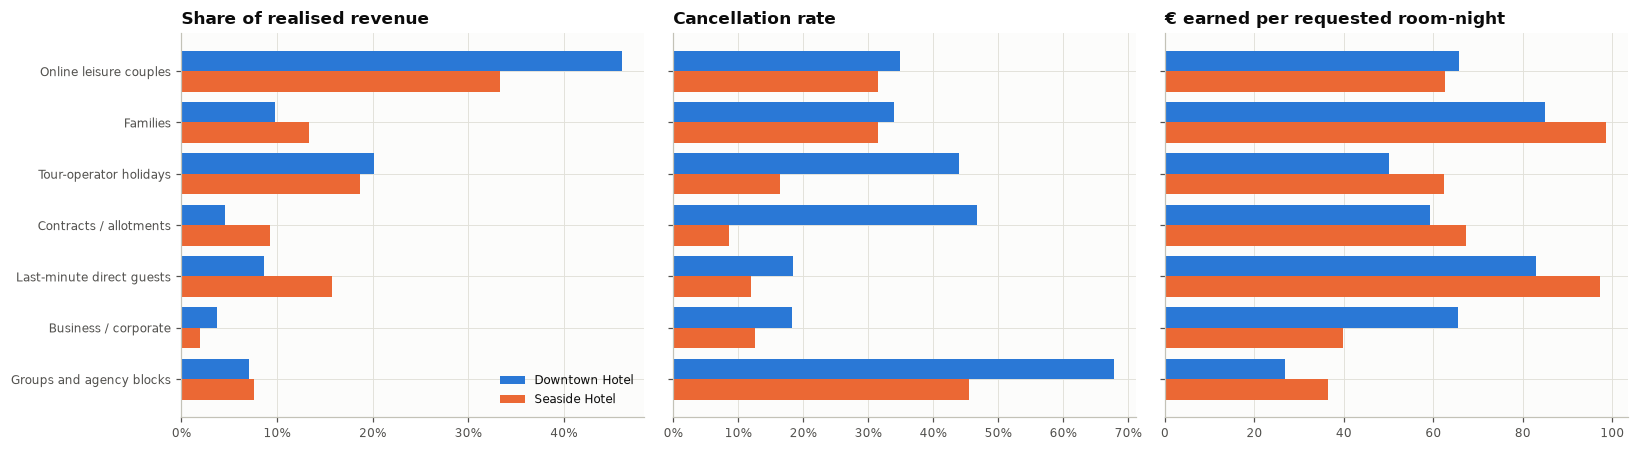

In [10]:
comp = pd.concat({h: cards[h][["revenue_share", "share_requested_room_nights", "cancel_rate", "yield_per_requested_night"]]
                  for h in HOTELS}, names=["hotel", "persona"]).reset_index()
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, col, title, f in [(axes[0], "revenue_share", "Share of realised revenue", P.PCT),
                          (axes[1], "cancel_rate", "Cancellation rate", P.PCT),
                          (axes[2], "yield_per_requested_night", "€ earned per requested room-night", None)]:
    t = comp.pivot(index="persona", columns="hotel", values=col).reindex(PERSONA_ORDER)
    y = np.arange(len(t))
    for i, h in enumerate(HOTELS):
        ax.barh(y + (i - .5) * .4, t[h], .4, color=P.HOTEL_COLORS[h], label=h)
    ax.set_yticks(y, t.index if ax is axes[0] else []); ax.invert_yaxis(); ax.set_title(title)
    if f: ax.xaxis.set_major_formatter(f)
axes[0].legend(loc="lower right")
P.save(fig, "personas_by_hotel")
plt.tight_layout(); plt.show()

**Same personas, different businesses.** Both hotels sell mostly to online couples, but the
risk sits in different places: at Downtown in agency blocks and tour operators (44–68%
cancellations), at Seaside mainly in groups (46%), while its tour operators and contracts are the
most reliable customers in the data. Families and direct guests are the most valuable per room
at both hotels.

## Takeaways

| Finding | Consequence for the system |
|---|---|
| 7–8 stable, explainable personas per hotel, recognisable at request time | personas are a vocabulary to *explain* decisions; the model sees the same raw signals |
| Channel is the main axis, but families and blocks cut across it | the model needs interactions (hotel × segment × party): tree models and the stack |
| Families and direct guests earn ~€85–99 per requested room-night, groups €27–36 | rank requests by value *per room-night*, not by stay value |
| Same label (tour operator) is risky at Downtown and reliable at Seaside | hotel is a feature; agent history separates good and bad partners |

Notebook 05 turns these personas into economics: value against risk, peak nights, booking timing,
partners and recommendations.